## Load and Inspect (Pandas)

In [133]:
import pandas as pd
import numpy as np

In [134]:
df = pd.read_excel('online_retail_II.xlsx')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


## Count missing values in the dataset

In [135]:
df.isnull().sum()


Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

## Find rows that contain at least one missing value

In [136]:
missing_rows = df[df.isnull().any(axis = 1)]
missing_rows

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
525231,538159,21324,NaN,-18,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525232,538158,20892,NaN,-32,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525233,538160,20956,NaN,288,2010-12-09 17:18:00,0.00,NaN,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom


## Missing data

In [137]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": round(df.isnull().mean()*100, 2)
})
missing

,Missing Count,Missing %
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


## Dealing with missing customer ID

In [138]:
sales_df = df.copy()
df = df.dropna(subset=["Customer ID"]).copy()

In [139]:
print(df.shape)
print(sales_df.shape)

(417534, 8)
(525461, 8)


## Dealing with missing Description
- Check if description exists somewhere else
- if not replace

In [140]:
df.groupby("StockCode")["Description"].unique()

StockCode
10002      [INFLATABLE POLITICAL GLOBE ]
10080         [GROOVY CACTUS INFLATABLE]
10109             [BENDY COLOUR PENCILS]
10120                     [DOGGY RUBBER]
10125          [MINI FUNKY DESIGN TAPES]
                       ...              
PADS        [PADS TO MATCH ALL CUSHIONS]
POST                           [POSTAGE]
SP1002          [KID'S CHALKBOARD/EASEL]
TEST001        [This is a test product.]
TEST002        [This is a test product.]
Name: Description, Length: 4031, dtype: object

In [141]:
df["Description"] = (
    df.groupby("StockCode")["Description"].transform(lambda x:x.ffill().bfill() )
)
df["Description"] = df["Description"].fillna("Unknown Product")

In [142]:
df.isnull().sum()


Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [143]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


## Quantity being negative:
- It means that:
    - there were returns 
    - or cancellations


In [144]:
df["isReturned"] = np.where(df["Quantity"] <0, True, False)
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,isReturned
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False
...,...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,False
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False


In [145]:
df[df["isReturned"]]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,isReturned
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True
...,...,...,...,...,...,...,...,...,...
524695,C538123,22956,36 FOIL HEART CAKE CASES,-2,2010-12-09 15:41:00,2.10,12605.0,Germany,True
524696,C538124,M,Manual,-4,2010-12-09 15:43:00,0.50,15329.0,United Kingdom,True
524697,C538124,22699,ROSES REGENCY TEACUP AND SAUCER,-1,2010-12-09 15:43:00,2.95,15329.0,United Kingdom,True
524698,C538124,22423,REGENCY CAKESTAND 3 TIER,-1,2010-12-09 15:43:00,12.75,15329.0,United Kingdom,True


## Invoices with cancelled orders

In [146]:
df["isCancelled"] = df["Invoice"].astype(str).str.startswith("C")
cancelled_orders = df[df["isCancelled"]]

# Create the Revenue Column

In [147]:
df["Revenue"] = df["Price"] * df["Quantity"]
df["isRevenue"]=df["Revenue"]<0
df[df["isRevenue"]]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,isReturned,isCancelled,Revenue,isRevenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True,True,-35.40,True
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,True,True,-9.90,True
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,True,True,-17.00,True
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,True,True,-12.60,True
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,True,True,-35.40,True
...,...,...,...,...,...,...,...,...,...,...,...,...
524695,C538123,22956,36 FOIL HEART CAKE CASES,-2,2010-12-09 15:41:00,2.10,12605.0,Germany,True,True,-4.20,True
524696,C538124,M,Manual,-4,2010-12-09 15:43:00,0.50,15329.0,United Kingdom,True,True,-2.00,True
524697,C538124,22699,ROSES REGENCY TEACUP AND SAUCER,-1,2010-12-09 15:43:00,2.95,15329.0,United Kingdom,True,True,-2.95,True
524698,C538124,22423,REGENCY CAKESTAND 3 TIER,-1,2010-12-09 15:43:00,12.75,15329.0,United Kingdom,True,True,-12.75,True


## Dealing with duplicate rows

In [148]:
duplicates = df.duplicated().sum()
print(duplicates)
df = df.drop_duplicates()
print(duplicates)


6771
6771


In [149]:
cancelled_orders = df[df["isCancelled"]]

## Date: Convert into year, month, day

In [150]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['Day'] = df['InvoiceDate'].dt.day_name()

/var/folders/zn/ggs3lqq15xn25m97nybf6vsw0000gn/T/ipykernel_88942/2151890790.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
/var/folders/zn/ggs3lqq15xn25m97nybf6vsw0000gn/T/ipykernel_88942/2151890790.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Year'] = df['InvoiceDate'].dt.year
/var/folders/zn/ggs3lqq15xn25m97nybf6vsw0000gn/T/ipykernel_88942/2151890790.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

In [151]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,isReturned,isCancelled,Revenue,isRevenue,Year,Month,Day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.40,False,2009,12,Tuesday
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.00,False,2009,12,Tuesday
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.00,False,2009,12,Tuesday
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.80,False,2009,12,Tuesday
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.00,False,2009,12,Tuesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,False,False,5.90,False,2010,12,Thursday
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,3.75,False,2010,12,Thursday
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,3.75,False,2010,12,Thursday
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,7.50,False,2010,12,Thursday


In [152]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 410763 entries, 0 to 525460
Data columns (total 15 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      410763 non-null  object        
 1   StockCode    410763 non-null  object        
 2   Description  410763 non-null  object        
 3   Quantity     410763 non-null  int64         
 4   InvoiceDate  410763 non-null  datetime64[ns]
 5   Price        410763 non-null  float64       
 6   Customer ID  410763 non-null  float64       
 7   Country      410763 non-null  object        
 8   isReturned   410763 non-null  bool          
 9   isCancelled  410763 non-null  bool          
 10  Revenue      410763 non-null  float64       
 11  isRevenue    410763 non-null  bool          
 12  Year         410763 non-null  int32         
 13  Month        410763 non-null  int32         
 14  Day          410763 non-null  object        
dtypes: bool(3), datetime64[ns](1), float64(

In [153]:
df.describe()


,Quantity,InvoiceDate,Price,Customer ID,Revenue,Year,Month
count,410763.000000,410763,410763.000000,410763.000000,410763.000000,410763.000000,410763.000000
mean,12.923735,2010-06-30 19:56:14.853674752,3.908358,15353.621857,20.242465,2009.923859,7.393339
min,-9360.000000,2009-12-01 07:45:00,0.000000,12346.000000,-25111.090000,2009.000000,1.000000
25%,2.000000,2010-03-26 09:46:00,1.250000,13979.000000,4.500000,2010.000000,4.000000
50%,5.000000,2010-07-08 15:09:00,1.950000,15311.000000,11.800000,2010.000000,8.000000
75%,12.000000,2010-10-14 12:32:00,3.750000,16797.000000,19.500000,2010.000000,11.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,15818.400000,2010.000000,12.000000
std,102.039550,NaN,71.714794,1681.657665,100.710825,0.265224,3.474156


In [154]:
df["Revenue"].describe()

count    410763.000000
mean         20.242465
std         100.710825
min      -25111.090000
25%           4.500000
50%          11.800000
75%          19.500000
max       15818.400000
Name: Revenue, dtype: float64

In [155]:
df["Country"].value_counts()

Country
United Kingdom          372705
EIRE                      8705
Germany                   8120
France                    5692
Netherlands               2768
Spain                     1271
Switzerland               1187
Belgium                   1053
Portugal                  1023
Channel Islands            906
Sweden                     882
Italy                      729
Australia                  654
Cyprus                     546
Austria                    537
Greece                     517
Denmark                    428
Norway                     369
Finland                    354
United Arab Emirates       318
Unspecified                280
USA                        244
Japan                      224
Poland                     194
Malta                      172
Lithuania                  154
Singapore                  117
Canada                      77
Thailand                    76
Israel                      74
Iceland                     71
RSA                         65


# Top 10 selling products

In [156]:
df.groupby("Description")["Quantity"].sum().sort_values(ascending = False).head(10)

Description
WHITE HANGING HEART T-LIGHT HOLDER    55760
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54130
BROCADE RING PURSE                    47430
PACK OF 72 RETRO SPOT CAKE CASES      44480
ASSORTED COLOUR BIRD ORNAMENT         44000
60 TEATIME FAIRY CAKE CASES           35480
PACK OF 60 PINK PAISLEY CAKE CASES    30753
JUMBO BAG RED RETROSPOT               29439
BLACK AND WHITE PAISLEY FLOWER MUG    25679
SMALL POPCORN HOLDER                  25379
Name: Quantity, dtype: int64

# Top Revenue Products

In [157]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending = False).head(10)

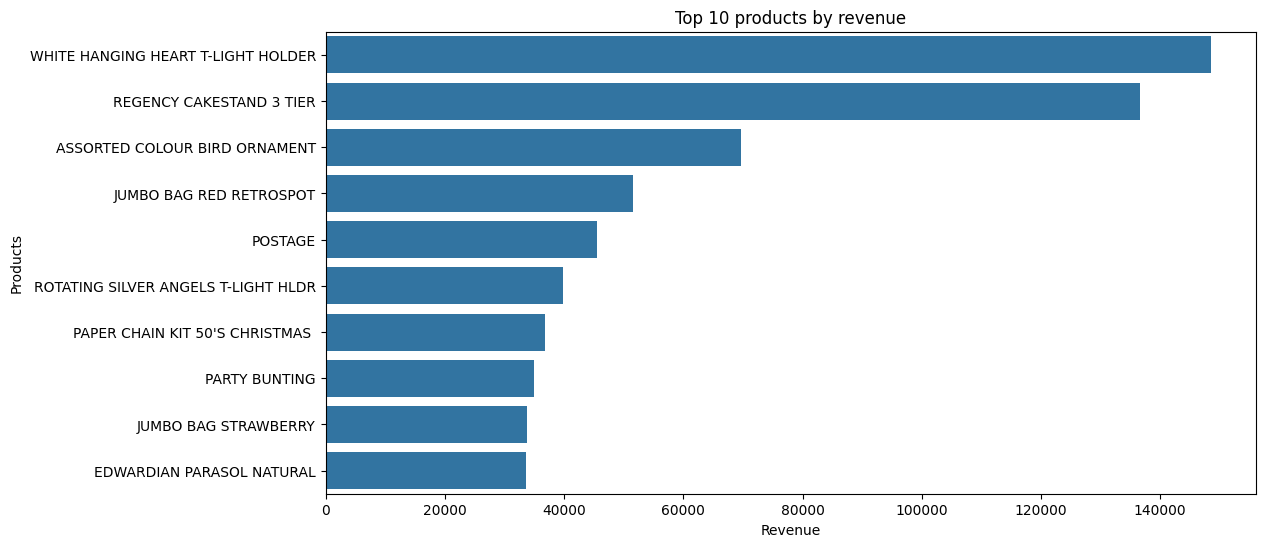

In [158]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(x = top_products.values, y = top_products.index)

plt.title("Top 10 products by revenue")
plt.xlabel("Revenue")
plt.ylabel("Products")
plt.show()

# Revenue by Country

In [159]:
top_countries  = df.groupby("Country")["Revenue"].sum().sort_values(ascending = False).head(10)
top_countries

Country
United Kingdom    7005793.443
EIRE               328234.260
Netherlands        263861.760
Germany            195920.421
France             129665.480
Sweden              50836.110
Denmark             46972.950
Switzerland         43343.410
Spain               37052.130
Australia           30051.800
Name: Revenue, dtype: float64

# Monthy Revenue

## Revenue by calendar month (seasonality)

In [160]:
import calendar
revenue_by_month = (
    df.groupby("Month")["Revenue"]
      .sum()
      .rename(index=lambda x: calendar.month_name[x])
      .sort_values(ascending=False)
)
print(revenue_by_month)

Month
November     1129025.162
December      963526.820
October       961520.740
September     778520.051
March         633419.311
August        585259.460
June          568784.550
July          560885.330
April         558007.832
May           557873.390
January       530436.512
February      487596.426
Name: Revenue, dtype: float64


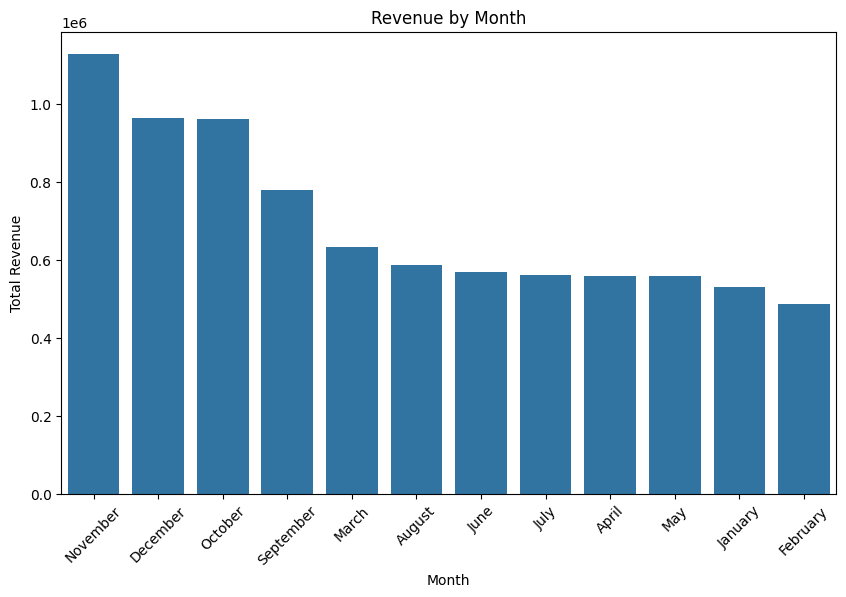

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    x=revenue_by_month.index,
    y=revenue_by_month.values
)

plt.title("Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.show()

## Revenue by Year-Month (time trend)

In [162]:
monthly_revenue = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"]
      .sum()
)

print(monthly_revenue)

InvoiceDate
2009-12     660125.100
2010-01     530436.512
2010-02     487596.426
2010-03     633419.311
2010-04     558007.832
2010-05     557873.390
2010-06     568784.550
2010-07     560885.330
2010-08     585259.460
2010-09     778520.051
2010-10     961520.740
2010-11    1129025.162
2010-12     303401.720
Freq: M, Name: Revenue, dtype: float64


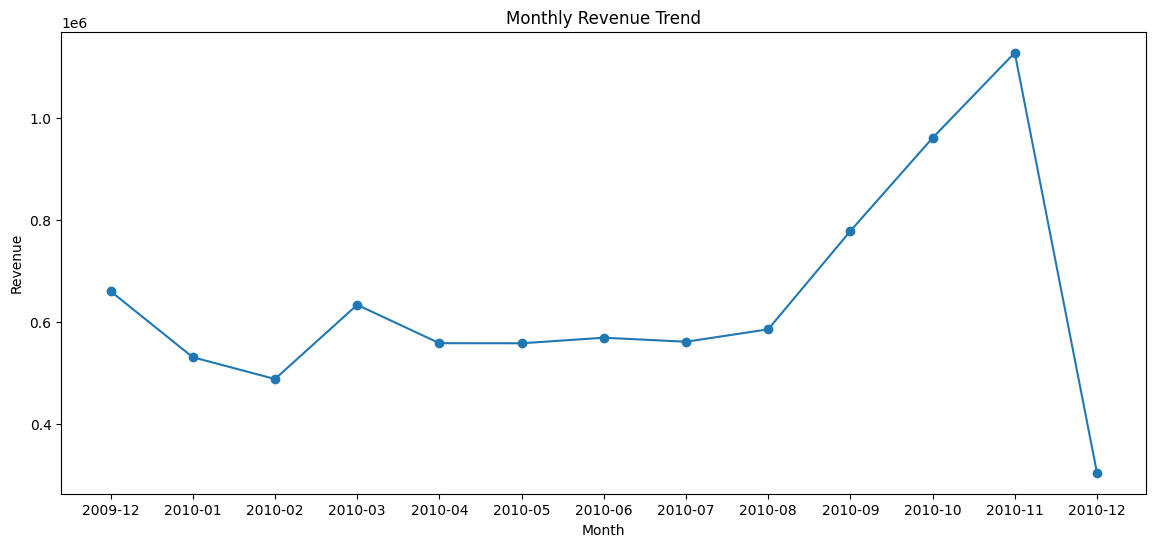

In [163]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker = "o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [164]:
monthly_revenue = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"]
      .sum()
      .sort_values(ascending = False)
)

print(monthly_revenue)

InvoiceDate
2010-11    1129025.162
2010-10     961520.740
2010-09     778520.051
2009-12     660125.100
2010-03     633419.311
2010-08     585259.460
2010-06     568784.550
2010-07     560885.330
2010-04     558007.832
2010-05     557873.390
2010-01     530436.512
2010-02     487596.426
2010-12     303401.720
Freq: M, Name: Revenue, dtype: float64


# Revenue Lost by cancelled orders

In [165]:
lost_revenue =np.abs(cancelled_orders["Revenue"].sum())
print(f"Revenue lost by cancelled orders is: {lost_revenue}")

Revenue lost by cancelled orders is: 483378.16000000003


# Percentage of revenue lost

In [166]:
total_sales = df[df["Revenue"]>0]["Revenue"].sum()
loss_percent = (lost_revenue/total_sales)*100
print(f"Loss Percentage: {loss_percent}%")

Loss Percentage: 5.494036349393903%


# Number of cancelled Transactions

In [167]:
cancelled_count = df["isCancelled"].sum()
print(f"Number of cancelled orders: {cancelled_count}")

Number of cancelled orders: 9816


# Top cancelled products

In [168]:
returned = cancelled_orders.groupby("Description")["Quantity"] \
    .sum() \
    .abs() \
    .sort_values(ascending = False) \
    .head(10)

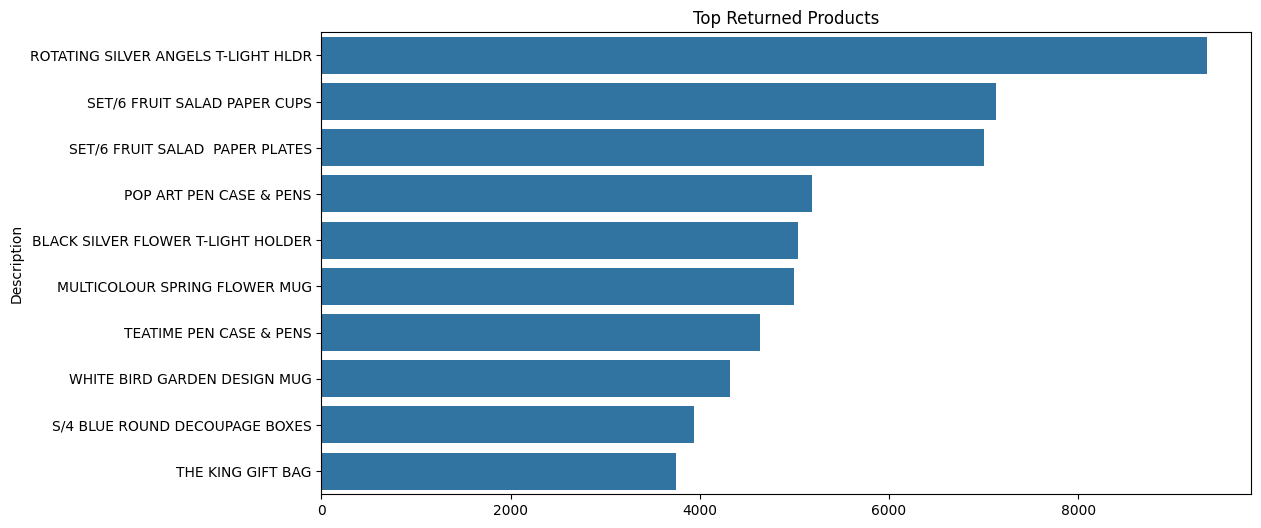

In [169]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=returned.values,
    y=returned.index
)

plt.title("Top Returned Products")
plt.show()

# Countries with most cancellations

In [170]:
cancelled_orders.groupby("Country")["Revenue"] \
    .sum() \
    .abs() \
    .sort_values(ascending = False)

Country
United Kingdom          375850.99
EIRE                     27807.60
Norway                   19864.61
France                   16441.59
Spain                    10516.52
Germany                   6104.97
Netherlands               4922.59
Denmark                   3933.90
Channel Islands           3179.00
Malta                     2686.75
Sweden                    2311.88
Belgium                   1893.55
Australia                 1395.00
Japan                     1286.06
Italy                     1278.34
Unspecified               1236.89
Switzerland                577.98
Portugal                   499.77
Austria                    391.05
Poland                     252.85
USA                        230.85
Finland                    191.75
Cyprus                     173.30
Korea                      168.69
United Arab Emirates       130.98
Greece                      50.70
Name: Revenue, dtype: float64

# Missing Customer IDs (Data Quality)

In [171]:
missing_cust= sales_df["Customer ID"].isna().sum()
missing_cust_per = sales_df["Customer ID"].isna().mean()
print(f"Missing customer ID's: {missing_cust}")
print(f"Missing customer ID's %: {missing_cust_per*100}%")


Missing customer ID's: 107927
Missing customer ID's %: 20.53948818275762%


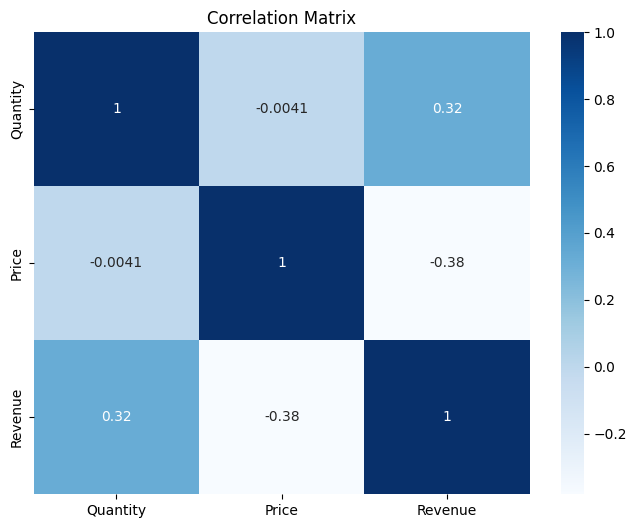

In [172]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[["Quantity","Price","Revenue"]].corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Matrix")
plt.show()

# RFM
### Recency - 
### Frequency - 
### Monetary - 

In [173]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,isReturned,isCancelled,Revenue,isRevenue,Year,Month,Day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.40,False,2009,12,Tuesday
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.00,False,2009,12,Tuesday
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.00,False,2009,12,Tuesday
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.80,False,2009,12,Tuesday
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.00,False,2009,12,Tuesday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,False,False,5.90,False,2010,12,Thursday
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,3.75,False,2010,12,Thursday
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,3.75,False,2010,12,Thursday
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,False,False,7.50,False,2010,12,Thursday


In [174]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days = 1)
# Customers latest purchase date
last_purchase = df.groupby("Customer ID")["InvoiceDate"].max()
# Recency
recency = (snapshot_date - last_purchase).dt.days
recency = recency.rename("Recency")
recency.head()

Customer ID
12346.0    67
12347.0     3
12348.0    74
12349.0    43
12351.0    11
Name: Recency, dtype: int64

In [175]:
df_valid = df[(~df["isCancelled"]) & (df["Price"] > 0)] #Exclude cancelled orders

frequency = df_valid.groupby("Customer ID")["Invoice"].nunique()
frequency.head()

Customer ID
12346.0    11
12347.0     2
12348.0     1
12349.0     3
12351.0     1
Name: Invoice, dtype: int64

In [176]:
monetary = df_valid.groupby("Customer ID")["Revenue"].sum()
monetary.head()

Customer ID
12346.0     372.86
12347.0    1323.32
12348.0     222.16
12349.0    2671.14
12351.0     300.93
Name: Revenue, dtype: float64

In [177]:
rfm = pd.concat([recency, frequency, monetary], axis=1)
rfm.columns = ["Recency", "Frequency", "Monetary"]
rfm = rfm.dropna()
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,67,11.0,372.86
12347.0,3,2.0,1323.32
12348.0,74,1.0,222.16
12349.0,43,3.0,2671.14
12351.0,11,1.0,300.93


In [178]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5,4,3,2,1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5])
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1,2,3,4,5])

In [179]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346.0,67,11.0,372.86,3,5,2
12347.0,3,2.0,1323.32,5,2,4
12348.0,74,1.0,222.16,2,1,1
12349.0,43,3.0,2671.14,3,3,5
12351.0,11,1.0,300.93,5,1,2


In [180]:
print(rfm.isna().sum())
print(len(rfm))

Recency      0
Frequency    0
Monetary     0
R_Score      0
F_Score      0
M_Score      0
dtype: int64
4312
